# Wine data science lab

Install the packages in requirements.txt, then run all cells from the repository root. The data comes from the [UCI Wine Recognition dataset](https://doi.org/10.24432/C5PC7J) via scikit-learn. AI assistance was used to prepare this notebook.

## Load and check the data

In [1]:
"""Run the internship exercises and export their results."""
from pathlib import Path
from statistics import mean, median, stdev

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

OUT = Path("results")
OUT.mkdir(exist_ok=True)
data = load_wine(as_frame=True)
raw = data.frame
clean = raw.drop_duplicates().dropna().copy()
X = clean.drop(columns="target")
y = clean.target
print("Rows, features:", len(raw), X.shape[1])
print("Missing cells:", raw.isna().sum().sum(), "Duplicate rows:", raw.duplicated().sum())
print("Class counts:", y.value_counts().sort_index().to_dict())
print("Alcohol mean, median, sample SD:", *(round(f(X.alcohol), 3) for f in (mean, median, stdev)))
summary = clean.groupby("target")[["alcohol", "flavanoids", "color_intensity"]].mean()
summary.to_csv(OUT / "class_means.csv")
print(summary.round(3).to_string())

Rows, features: 178 13
Missing cells: 0 Duplicate rows: 0
Class counts: {0: 59, 1: 71, 2: 48}
Alcohol mean, median, sample SD: 13.001 13.05 0.812
        alcohol  flavanoids  color_intensity
target                                      
0        13.745       2.982            5.528
1        12.279       2.081            3.087
2        13.154       0.781            7.396


## Explore class counts and measurements

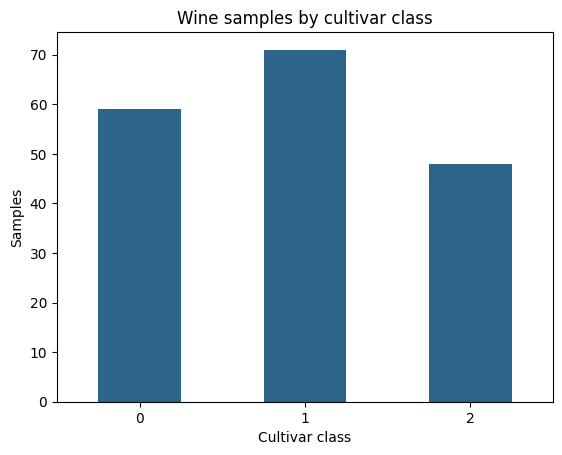

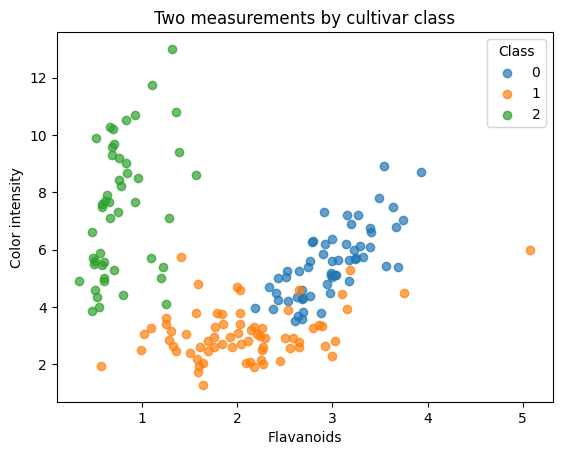

In [2]:
fig, ax = plt.subplots()
y.value_counts().sort_index().plot.bar(ax=ax, color="#2b668a", rot=0)
ax.set(xlabel="Cultivar class", ylabel="Samples", title="Wine samples by cultivar class")
fig.savefig(OUT / "class_counts.png", bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots()
for label, group in clean.groupby("target"):
    ax.scatter(group.flavanoids, group.color_intensity, label=str(label), alpha=.7)
ax.set(xlabel="Flavanoids", ylabel="Color intensity", title="Two measurements by cultivar class")
ax.legend(title="Class")
fig.savefig(OUT / "measurements.png", bbox_inches="tight")
plt.close(fig)

## Visualize two principal components

PCA variance: [0.362, 0.192]


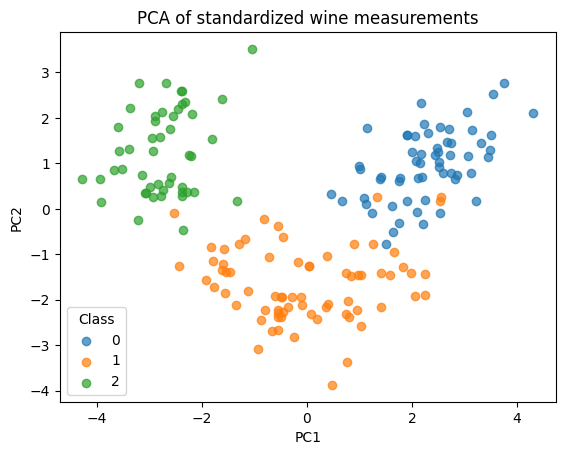

In [3]:
pca = PCA(n_components=2)
scores = pca.fit_transform(StandardScaler().fit_transform(X))
print("PCA variance:", pca.explained_variance_ratio_.round(3).tolist())
fig, ax = plt.subplots()
for label in sorted(y.unique()):
    points = scores[y.to_numpy() == label]
    ax.scatter(points[:, 0], points[:, 1], label=str(label), alpha=.7)
ax.set(xlabel="PC1", ylabel="PC2", title="PCA of standardized wine measurements")
ax.legend(title="Class")
fig.savefig(OUT / "pca.png", bbox_inches="tight")
plt.close(fig)

## Evaluate on held out samples

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.25, random_state=42, stratify=y
)
for name, model in [
    ("Majority baseline", DummyClassifier(strategy="most_frequent")),
    ("Logistic regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
]:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, "test samples:", len(y_test), "accuracy:", round(accuracy_score(y_test, pred), 4))
    print(confusion_matrix(y_test, pred, labels=sorted(y.unique())))

Majority baseline test samples: 45 accuracy: 0.4
[[ 0 15  0]
 [ 0 18  0]
 [ 0 12  0]]
Logistic regression test samples: 45 accuracy: 1.0
[[15  0  0]
 [ 0 18  0]
 [ 0  0 12]]


The plots are saved in results/. Logistic regression got 45 of 45 cases correct on this fixed split, compared with 18 of 45 for the majority baseline. This small benchmark does not establish performance on new batches.